Classification report
              precision    recall  f1-score   support

        Died       0.82      0.88      0.85       110
    Survived       0.78      0.68      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179

roc-auc score: 0.838


/home/ravi/Thesis/.venv/lib/python3.12/site-packages/sklearn/utils/_plotting.py:176: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


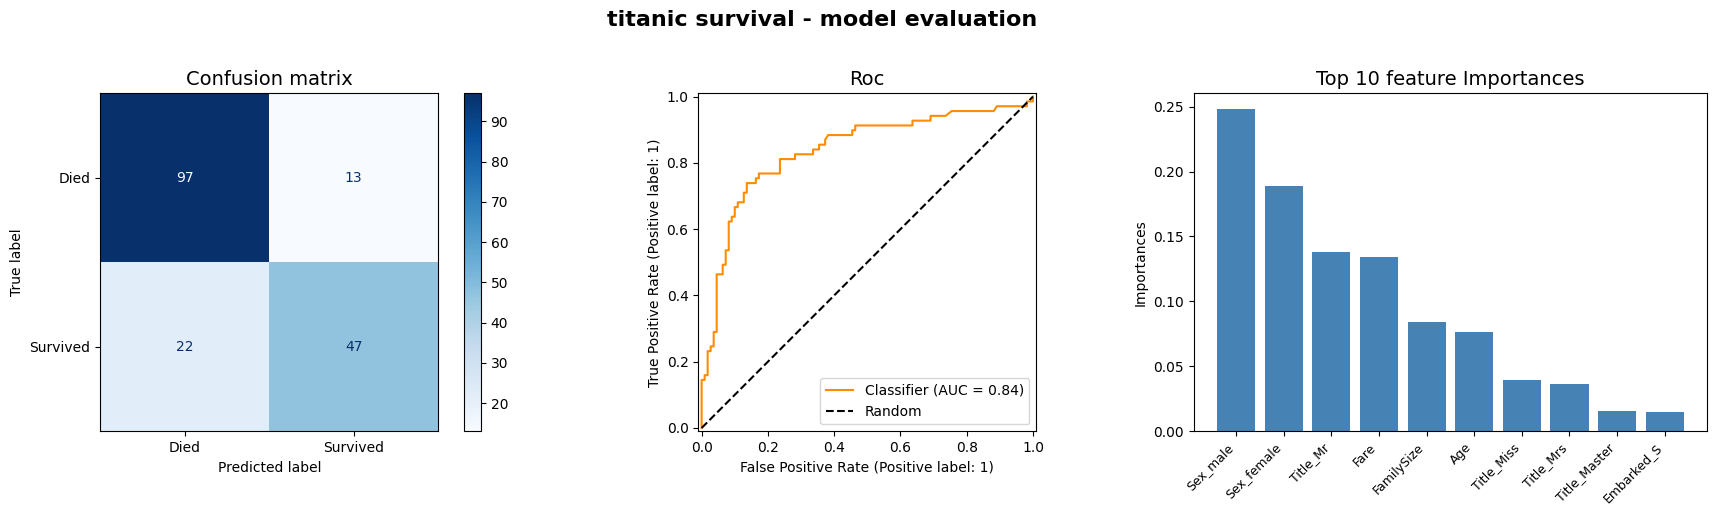

In [12]:
import sys
sys.path.insert(0, '/home/ravi/Thesis/ML ex/titanic-ml')

import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    roc_auc_score
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# ── Step 1: Load & prepare same data ────────────────────────
df = pd.read_csv('train.csv')

df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['IsAlone']    = (df['FamilySize'] == 1).astype(int)
df['Title']      = df['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
df['Title']      = df['Title'].replace(
    ['Lady','Countess','Capt','Col','Don','Dr',
     'Major','Rev','Sir','Jonkheer','Dona'], 'Rare')
df['Title']      = df['Title'].replace(
    {'Mlle':'Miss', 'Ms':'Miss', 'Mme':'Mrs'})

features = ['Age','Fare','FamilySize','IsAlone',
            'Pclass','Sex','Embarked','Title']
X = df[features]
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

with open('best_model.pkl', 'rb') as f:
    model = pickle.load(f)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("=" * 45)
print("Classification report")
print("=" * 45)
print(classification_report(y_test, y_pred, target_names=['Died', 'Survived']))
print(f"roc-auc score: {roc_auc_score(y_test, y_prob):.3f}")

fig, axes = plt.subplots(1,3, figsize=(18,5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Died', 'Survived'],
    cmap='Blues',
    ax=axes[0]
)

axes[0].set_title('Confusion matrix', fontsize=14)

RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1], color='darkorange')
axes[1].plot([0,1],[0,1], 'k--', label='Random')
axes[1].set_title('Roc', fontsize=14)
axes[1].legend()

rf_model = model.named_steps['model']
feat_names = model.named_steps['preprocessor'].get_feature_names_out()
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1][:10]

axes[2].bar(range(10), importances[indices], color='steelblue')
axes[2].set_xticks(range(10))
axes[2].set_xticklabels([feat_names[i].replace('num__','').replace('cat__','')
                          for i in indices], rotation=45, ha='right', fontsize=9)
axes[2].set_title('Top 10 feature Importances', fontsize=14)
axes[2].set_ylabel('Importances')

plt.suptitle('titanic survival - model evaluation', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('evaluation.png', dpi=150, bbox_inches='tight')
plt.show()
